<a id="top"></a>

# Netflix Content Analytics: End-to-End Data Analysis with Python

**Auspify Technologies · Data Analysis Using Python Internship · Tasks 1–6**
**Prepared by:** Furqaan

---

## Executive Overview

This notebook completes **all six** tasks of the Auspify *Data Analysis Using Python* task list on a single Netflix catalog dataset. It is written as one continuous, reproducible analysis: raw data goes in, a validated clean dataset is produced in Task 1, and every later task builds on that clean dataset.

| # | Level | Task | What it delivers |
|---|-------|------|------------------|
| [1](#task1) | Easy | Data Cleaning & Preparation | Validated, analysis-ready dataset + cleaning log + export |
| [2](#task2) | Easy | Content Type Analysis Dashboard | Movies vs TV Shows distribution, proportions, summary |
| [3](#task3) | Medium | Country-Wise Content Analysis | Country rankings, concentration, geographic map, insights |
| [4](#task4) | Medium | Trend Analysis by Release Year | Yearly trends, growth/decline phases, seasonality |
| [5](#task5) | Advanced | Content Rating & Genre Analysis | Audience segmentation, interactive visuals, statistical tests |
| [6](#task6) | Advanced | Business Insights Report | EDA, three dashboards, recommendations, executive summary |

### Notebook conventions
* **Every number in the written findings is computed from the data** and inserted programmatically, so text and charts can never drift apart.
* **Data-quality decisions are explicit.** Each cleaning rule states what was found, what was done, and why.
* **Outputs** (cleaned CSV, all figures, summary files) are written to the `data/outputs/` folder next to this notebook.

### Requirements
`python >= 3.9` · `pandas` · `numpy` · `matplotlib` · `seaborn` · `plotly` · `scipy`
Install with: ` install pandas numpy matplotlib seaborn plotly scipy`

### Data dictionary (raw file)

| Column | Description |
|--------|-------------|
| `show_id` | Unique identifier of the title |
| `type` | Content type: `Movie` or `TV Show` |
| `title` | Title of the content |
| `director` | Director name(s); missing values are stored as the text `Not Given` |
| `country` | Country of production; missing values are stored as the text `Not Given` |
| `date_added` | Date the title was added to the platform (`m/d/yyyy` text) |
| `release_year` | Original release year |
| `rating` | Maturity rating (e.g. `TV-MA`, `PG-13`) |
| `duration` | Runtime in minutes for movies, number of seasons for TV shows (text) |
| `listed_in` | Comma-separated genre / category tags |

<a id="task2"></a>

---

# Task 2 · Content Type Analysis Dashboard  `Easy`

**Goal:** analyse the distribution of Movies and TV Shows on Netflix.

| Step | Activity |
|------|----------|
| 1 | Load the cleaned dataset |
| 2 | Calculate the total number of Movies and TV Shows |
| 3 | Create visualisations of the content distribution |
| 4 | Compare content proportions |
| 5 | Summarise key findings |

## Step 0. Setting up the envirnoment 

In [8]:
import pandas as pd 
import matplotlib.pyplot as plt 
from matplotlib.patches import Patch
import numpy as np

## Step 1. Loading the cleaned dataset

In [2]:
# setting up the data directory
DATA_DIR = '../data/output/cleaned_data.csv'

# loading the csv file from the 
df = pd.read_csv(filepath_or_buffer=DATA_DIR, 
                index_col=False)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8787 entries, 0 to 8786
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   show_id         8787 non-null   str  
 1   type            8787 non-null   str  
 2   title           8787 non-null   str  
 3   director        8787 non-null   str  
 4   country         8787 non-null   str  
 5   date_added      8787 non-null   str  
 6   release_year    8787 non-null   int64
 7   rating          8787 non-null   str  
 8   listed_in       8787 non-null   str  
 9   duration_value  8787 non-null   int64
 10  duration_unit   8787 non-null   str  
dtypes: int64(2), str(9)
memory usage: 755.3 KB


In [4]:
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,listed_in,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,Documentaries,90,min
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,"Crime TV Shows, International TV Shows, TV Act...",1,season
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,"TV Dramas, TV Horror, TV Mysteries",1,season
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,"Children & Family Movies, Comedies",91,min
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,"Dramas, Independent Movies, International Movies",125,min


## Step 2. claculate the total number of movies and TV shows 

In [159]:
_available_types = df['type'].value_counts()
total_type = _available_types.sum()

In [177]:
# setting the global fonts to bold
plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"

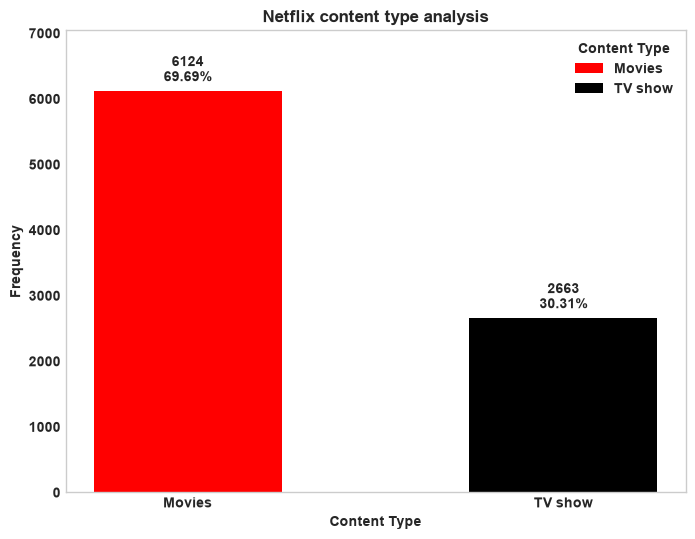

In [180]:
# setting up the data 
x_data = df.type.value_counts()

# instantiate the matplotlib figure 
fig, ax = plt.subplots(figsize=(8, 6))

# setting up the bar plot 
bar = ax.bar(x=["Movies", "TV show"], height=x_data.values, color=["red", 'black'], label=["Movies", "TV show"], width=0.5)

# setting up the bar ratio 
ax.bar_label(bar, labels=[f"{value}\n{(value / total_type) * 100:.2f}%" for value in _available_types.values], padding=4, fontweight='bold')

# styling up the axis 
ax.set(title="Netflix content type analysis", 
       xlabel="Content Type", 
       ylabel="Frequency",
      ylim=(0, _available_types.max() * 1.15))

# remove the background grid from the graph
ax.grid(visible=False)
ax.legend(title="Content Type")


plt.savefig("../data/output/figure/001_netlix_content_type.png");



In [174]:
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,listed_in,duration_value,duration_unit,release_era
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,Documentaries,90,min,2020+
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,"Crime TV Shows, International TV Shows, TV Act...",1,season,2020+
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,"TV Dramas, TV Horror, TV Mysteries",1,season,2020+
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,"Children & Family Movies, Comedies",91,min,2020+
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,"Dramas, Independent Movies, International Movies",125,min,≤1999


## Step - 3. Visualization of content Distribution 

In [175]:
plt.style.use("seaborn-v0_8-whitegrid")

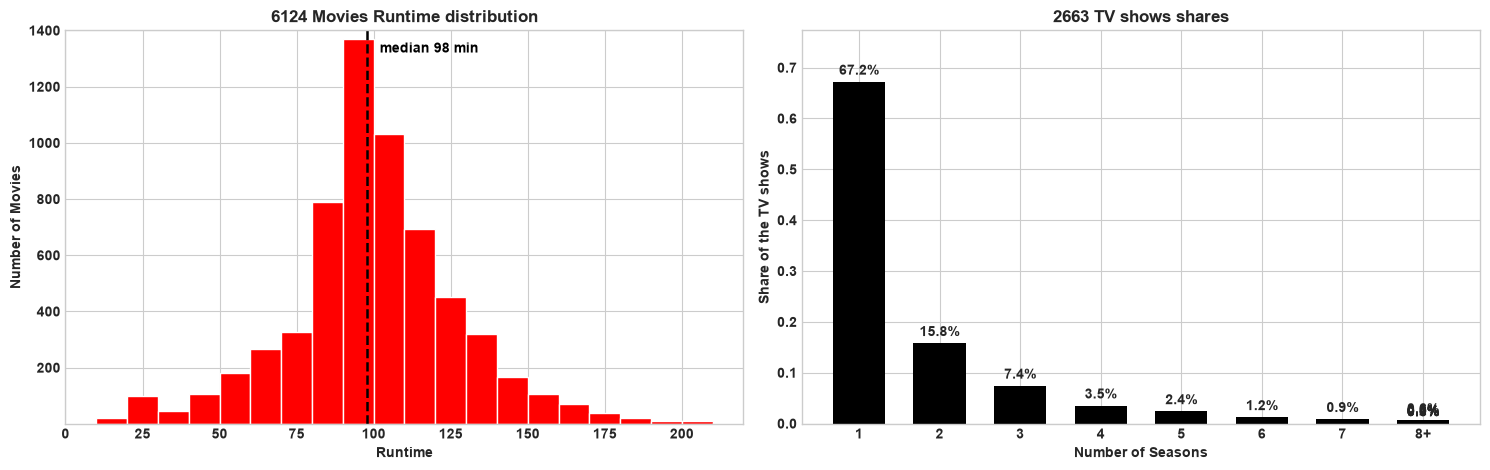

In [181]:
# fetch only movie data 
movies = df.loc[df["type"] == "Movie", "duration_value"]

fig, axis = plt.subplots(nrows=1, ncols=2, figsize=(15, 4.8))

# instantiate the histogram for the ploting of the data 
ax = axis[0] 
ax.hist(x=movies,
       bins=np.arange(0, 250, 10),
       color='Red',
       edgecolor='white')
ax.axvline(x=movies.median(),color='black', ls="--", lw=1.8)
ax.text(movies.median() + 4, ax.get_ylim()[1] * 0.92, f"median {movies.median():.0f} min", color="black", fontweight="bold")
ax.set_xlim(0, 220)
ax.set_ylim(1, 1400)
ax.set_xlabel("Runtime")
ax.set_ylabel("Number of Movies")
ax.set_title(f"{len(movies)} Movies Runtime distribution")

ax = axis[1]
# fetch the TV shows from the dataframe 
tv_shows = df.loc[df["type"] == "TV Show", "duration_value"]

# fetch the unique tv shows season like 1,2,3,4.......,
unique_tv_shows = tv_shows.value_counts(normalize=True).sort_index()

# instatiate the graph 

bar_plot = ax.bar(x=[str(season) if season < 8 else "8+" for season in unique_tv_shows.index], 
       height=unique_tv_shows.values,
      color='black',
      width=0.65)
ax.set(xlabel="Number of Seasons",
      ylabel="Share of the TV shows",
      title=f"{len(tv_shows)} TV shows shares",
      ylim=(0, unique_tv_shows.max() * 1.15))

ax.bar_label(bar_plot, labels=[f"{label:.1%}" for label in unique_tv_shows.values],
            padding=3)


fig.tight_layout()

plt.savefig("../data/output/figure/002_runtime_distribution.png");

plt.show()

In [131]:
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,listed_in,duration_value,duration_unit,release_era
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,Documentaries,90,min,2020+
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,"Crime TV Shows, International TV Shows, TV Act...",1,season,2020+
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,"TV Dramas, TV Horror, TV Mysteries",1,season,2020+
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,"Children & Family Movies, Comedies",91,min,2020+
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,"Dramas, Independent Movies, International Movies",125,min,≤1999


In [143]:
x_data.values

array([6124, 2663])

In [147]:
len(movies)

6124